# Scaling Law Experiment — Linear Regression

This notebook implements the synthetic diagonal linear-regression model and compares
**Heavy Ball (HB)**, **Nesterov (NAG)**, and **SGD** under the **same data-budget scaling**.

The experiment now uses a single configurable source parameter `S_VALUE`. The scaling is
$B=C_BD^{(2s+1)/(2s+2)}$, $K=C_KD^{1/(2s+2)}$,
$\eta=0.05$, and $1-\rho=C_\rho D^{-1/(2s+2)}$.
The reference optimal log--log slope is

$$
-\frac{s}{s+1}.
$$

All three algorithms use the same $B,K,\eta$ scaling; HB and NAG additionally use
the scheduled momentum $\rho$, while SGD keeps $\rho=0$ by definition.


## 1. Setting

$$
\text{Label:}\quad y=\langle\theta^*,x\rangle+\varepsilon,\quad \varepsilon\sim\mathcal{N}(0,\sigma^2)
$$
$$
\text{Data:}\quad x\sim\mathcal{N}(0,H),\qquad H=\mathrm{diag}(\lambda_i),\qquad \lambda_i\asymp i^{-\beta}
$$
$$
\text{Task:}\quad \theta_j^{*\,2}\sim j^{-1-(s-1)\beta}
$$

Because $H$ is diagonal, we work directly in the eigenbasis: each coordinate is independent with
$x_j\sim\mathcal{N}(0,\lambda_j)$. The **population** (test) loss splits into an irreducible part
and the **excess loss**
$$
L(\theta)=\tfrac12\sigma^2+\underbrace{\tfrac12(\theta-\theta^*)^\top H(\theta-\theta^*)}_{\mathcal{E}(\theta)},
\qquad
\mathcal{E}(\theta)=\tfrac12\sum_j \lambda_j\,(\theta_j-\theta_j^*)^2 .
$$
We evaluate $\mathcal{E}$ **analytically** (it is the exact population excess loss), which is both
exact and cheaper than a Monte-Carlo test set.


In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# ======================== GPU / CPU 后端自动选择 ========================
try:
    import cupy as cp
    import cupy.random as cpr
    USE_GPU = True
    print("Using GPU (CuPy)")
except ImportError:
    import numpy as cp
    import numpy.random as cpr
    USE_GPU = False
    print("Using CPU (NumPy)")
# =======================================================================

# ----------------------------- model / task parameters -----------------------------
BETA  = 2     # spectrum decay lambda_j ~ j^{-beta} (beta > 1)
SIGMA = 0.1     # label-noise std
DIM   = 4096    # ambient dimension (truncation of the infinite spectrum)

# Single source-smoothness parameter for this experiment.
# Change only this value if you want to rerun the D-sweep for a different s.
S_VALUE = 1.50
S_CASES = [
    {'key': f's_{S_VALUE:g}'.replace('.', '_'), 'title': rf'$s={S_VALUE:.2f}$', 's': S_VALUE},
]

def build_problem(dim=DIM, beta=BETA, s=1.0):
    """返回 (lam, theta_star) 用于对角线性回归问题"""
    j = cp.arange(1, dim + 1, dtype=cp.float64)
    lam = j ** (-beta)
    var_star = j ** (-(1.0 + (s - 1.0) * beta))
    theta_star = cp.sqrt(var_star)
    return lam, theta_star

def excess_loss(delta, lam):
    """精确的群体超额损失 E = 1/2 * sum_j lam_j * delta_j^2"""
    return 0.5 * cp.sum(lam * delta * delta)

print(f'beta={BETA}, sigma={SIGMA}, dim={DIM}')
for case in S_CASES:
    lam, theta_star = build_problem(s=case['s'])
    print(f"{case['title']:>10s}: s={case['s']:.3f}, "
          f"lambda range [{float(lam[-1]):.2e}, {float(lam[0]):.2e}], "
          f"initial excess loss E(0)={float(excess_loss(-theta_star, lam)):.4f}")

Using GPU (CuPy)
beta=2, sigma=0.1, dim=4096
  $s=1.50$: s=1.500, lambda range [5.96e-08, 1.00e+00], initial excess loss E(0)=0.5412


## 2. Data generation & stochastic gradient

For a minibatch of size $B$ we draw fresh samples $x_i\sim\mathcal{N}(0,H)$ and
$y_i=\langle\theta^*,x_i\rangle+\varepsilon_i$. Writing $\delta=\theta-\theta^*$, the empirical
gradient is
$$
\nabla\hat L(\theta)=\frac1B\sum_{i=1}^B\big(\langle\delta,x_i\rangle-\varepsilon_i\big)\,x_i
= H\delta+\xi,\qquad \xi\ \text{the gradient noise}.
$$
We run a **single pass** over the data, so the total number of samples consumed is
$B\cdot K \approx D$ — this is exactly the data budget $D$ used in the scaling analysis.
Tracking $\delta$ directly (instead of $\theta$) is convenient because $\theta^*$ is constant and
all update rules are affine in $\delta$.


In [2]:
def sample_batch(B, lam, sigma=SIGMA, rng=None):
    """绘制一个小批量。返回 X (B,d) 和 eps (B,)。"""
    if rng is None:
        rng = cp.random.RandomState()
    d = lam.shape[0]
    X = rng.standard_normal((B, d)) * cp.sqrt(lam)
    eps = rng.standard_normal(B) * sigma
    return X, eps

def grad_delta(delta, X, eps):
    """经验损失的随机梯度（以 delta = theta - theta* 表示）。"""
    B = X.shape[0]
    resid = X @ delta - eps
    return (X.T @ resid) / B

## 3. Algorithms

All three share the affine recursion in $\delta_t=\theta_t-\theta^*$ (initialised at $\theta_0=0$,
i.e. $\delta_0=-\theta^*$).

**Heavy Ball (HB).**
$$\theta_{t+1}=\theta_t-\eta\,\nabla\hat L(\theta_t)+\rho\,(\theta_t-\theta_{t-1}).$$

**Nesterov (NAG).** Gradient evaluated at the extrapolated point:
$$\theta_{t+1}=\theta_t-\eta\,\nabla\hat L\big(\theta_t+\rho(\theta_t-\theta_{t-1})\big)+\rho\,(\theta_t-\theta_{t-1}).$$

**SGD.** The special case $\rho=0$:
$$\theta_{t+1}=\theta_t-\eta\,\nabla\hat L(\theta_t).$$

Each step consumes one fresh minibatch of size $B$; we run $K$ steps and return the final excess loss.


In [3]:
def run_optimizer(algo, B, K, eta, rho, lam, theta_star, sigma=SIGMA, rng=None):
    """运行 {'hb','nag','sgd'} 之一，共 K 步，批量大小 B。返回 (final_E, curve)。"""
    if rng is None:
        rng = cp.random.RandomState()
    if algo == 'sgd':
        rho = 0.0
    delta = -theta_star.copy()
    delta_prev = delta.copy()
    curve = cp.empty(K + 1)
    curve[0] = excess_loss(delta, lam)
    for t in range(K):
        X, eps = sample_batch(B, lam, sigma=sigma, rng=rng)
        momentum = delta - delta_prev
        if algo == 'nag':
            g = grad_delta(delta + rho * momentum, X, eps)
        else:
            g = grad_delta(delta, X, eps)
        delta_new = delta - eta * g + rho * momentum
        delta_prev, delta = delta, delta_new
        curve[t + 1] = excess_loss(delta, lam)
    return float(curve[-1]), cp.asnumpy(curve)

## 4. Requested scaling with the same $B,K,\eta$ for all algorithms

Use the requested schedule

$$
B=C_BD^{\frac{2s+1}{2s+2}},\qquad
K=C_KD^{\frac{1}{2s+2}},\qquad
\eta=0.05,\qquad
1-\rho=C_\rho D^{-\frac{1}{2s+2}}.
$$

The default constants used below are $C_B=C_K=C_\rho=1$.

Equivalently, with $B=C_BD^a$, $K=C_KD^{1-a}$,
$1-\rho=C_\rho D^{-b}$, and $\eta=0.05$,

$$
a=\frac{2s+1}{2s+2},\qquad b=\frac{1}{2s+2},\qquad c=0,\qquad
p^*=\frac{s}{s+1}.
$$

The theoretical reference line in the log--log plots therefore has slope $-s/(s+1)$.


In [4]:
# ----------------------------- requested common scaling -----------------------------
C_B = 0.1
C_K = 10
C_RHO = 1.0
ETA_FIXED = 0.05


def requested_scaling(s):
    """Return the requested scaling exponents."""
    if s <= 0:
        raise ValueError(f's must be positive, got {s}')

    a = (2.0 * s + 1.0) / (2.0 * s + 2.0)
    b = 1.0 / (2.0 * s + 2.0)
    c = 0.0
    x = a + c - b
    y = a + b
    p_star = s / (s + 1.0)

    return {'a': a, 'b': b, 'c': c, 'x': x, 'y': y, 'p': p_star, 'p_star': p_star,
            'C_B': C_B, 'C_K': C_K, 'C_RHO': C_RHO}


def common_schedule(D, scaling):
    """B,K,eta,rho at data budget D using the same B,K,eta scaling for HB/NAG/SGD."""
    a, b = scaling['a'], scaling['b']
    c_b, c_k, c_rho = scaling['C_B'], scaling['C_K'], scaling['C_RHO']
    B = max(1, int(round(c_b * D ** a)))
    K = max(1, int(round(c_k * D ** (1.0 - a))))
    eta = ETA_FIXED
    one_minus_rho = min(1.0, c_rho * D ** (-b))
    rho = 1.0 - one_minus_rho
    return B, K, eta, rho

SCALINGS = {case['key']: requested_scaling(case['s']) for case in S_CASES}

for case in S_CASES:
    sc = SCALINGS[case['key']]
    print(f"{case['title']}  s={case['s']:.3f}")
    print(f"  exponents: a={sc['a']:.4f}, b={sc['b']:.4f}, c={sc['c']:.4f}, "
          f"x=a+c-b={sc['x']:.4f}, y=a+b={sc['y']:.4f}")
    print(f"  constants: C_B={sc['C_B']:.3g}, C_K={sc['C_K']:.3g}, C_RHO={sc['C_RHO']:.3g}")
    print(f"  scaling: B=C_B*D^a, K=C_K*D^(1-a), eta={ETA_FIXED:g}, 1-rho=C_RHO*D^(-b)")
    print(f"  theory exponent used: p=s/(s+1)={sc['p']:.4f}; slope=-{sc['p_star']:.4f}")
    for D in [2**10, 2**15]:
        B, K, eta, rho = common_schedule(D, sc)
        print(f"  D=2^{int(np.log2(D)):d}: B={B}, K={K}, eta={eta:.3g}, rho(HB/NAG)={rho:.4f}")
    print()


$s=1.50$  s=1.500
  exponents: a=0.8000, b=0.2000, c=0.0000, x=a+c-b=0.6000, y=a+b=1.0000
  constants: C_B=0.1, C_K=10, C_RHO=1
  scaling: B=C_B*D^a, K=C_K*D^(1-a), eta=0.05, 1-rho=C_RHO*D^(-b)
  theory exponent used: p=s/(s+1)=0.6000; slope=-0.6000
  D=2^10: B=26, K=40, eta=0.05, rho(HB/NAG)=0.7500
  D=2^15: B=410, K=80, eta=0.05, rho(HB/NAG)=0.8750



For the configured single $s$ and each $D$, the three algorithms share the same $B,K,\eta$ schedule.
Only the algorithmic momentum differs: HB and Nesterov use the scheduled $\rho$, while SGD uses
$\rho=0$.


In [5]:
D_EXPONENTS = list(range(10, 16))
D_LIST = [2 ** e for e in D_EXPONENTS]
D_ARRAY = np.array(D_LIST, dtype=float)
N_SEEDS = 5

ALGOS = {
    'HB'      : 'hb',
    'Nesterov': 'nag',
    'SGD'     : 'sgd',
}

CASE_RESULTS = {}

for case in S_CASES:
    key, s = case['key'], case['s']
    lam, theta_star = build_problem(s=s)
    scaling = SCALINGS[key]
    results = {name: {'mean': [], 'std': []} for name in ALGOS}

    print(f"=== {case['title']}  s={s:.3f}; common exponents "
          f"a={scaling['a']:.3f}, b={scaling['b']:.3f}, c={scaling['c']:.3f}; "
          f"theory p={scaling['p']:.3f} ===")

    for D in D_LIST:
        B, K, eta, rho = common_schedule(D, scaling)
        print(f"D=2^{int(np.log2(D)):<2d}  common B={B:<5d} K={K:<5d} eta={eta:.3g} rho={rho:.4f}")
        for name, algo in ALGOS.items():
            vals = []
            for seed in range(N_SEEDS):
                rng = cp.random.RandomState(10_000 * seed + 100 * int(10 * s) + D)
                final_E, _ = run_optimizer(algo, B, K, eta, rho, lam, theta_star, rng=rng)
                vals.append(final_E)
            vals = np.array(vals)
            results[name]['mean'].append(vals.mean())
            results[name]['std'].append(vals.std())
            print(f"  {name:9s} E_K={vals.mean():.3e} +/- {vals.std():.1e}")
    CASE_RESULTS[key] = {'case': case, 'scaling': scaling, 'results': results}
    print()


=== $s=1.50$  s=1.500; common exponents a=0.800, b=0.200, c=0.000; theory p=0.600 ===
D=2^10  common B=26    K=40    eta=0.05 rho=0.7500


  HB        E_K=3.254e-03 +/- 1.2e-04
  Nesterov  E_K=3.401e-03 +/- 1.3e-04
  SGD       E_K=2.703e-02 +/- 9.0e-04
D=2^11  common B=45    K=46    eta=0.05 rho=0.7824
  HB        E_K=2.279e-03 +/- 1.4e-04
  Nesterov  E_K=2.348e-03 +/- 1.1e-04
  SGD       E_K=2.137e-02 +/- 9.1e-04
D=2^12  common B=78    K=53    eta=0.05 rho=0.8105
  HB        E_K=1.495e-03 +/- 1.1e-04
  Nesterov  E_K=1.527e-03 +/- 1.0e-04
  SGD       E_K=1.695e-02 +/- 5.5e-04
D=2^13  common B=135   K=61    eta=0.05 rho=0.8351
  HB        E_K=9.383e-04 +/- 3.5e-05
  Nesterov  E_K=9.598e-04 +/- 3.9e-05
  SGD       E_K=1.365e-02 +/- 5.4e-04
D=2^14  common B=235   K=70    eta=0.05 rho=0.8564
  HB        E_K=6.364e-04 +/- 1.1e-05
  Nesterov  E_K=6.383e-04 +/- 5.3e-06
  SGD       E_K=1.132e-02 +/- 1.4e-04
D=2^15  common B=410   K=80    eta=0.05 rho=0.8750
  HB        E_K=4.430e-04 +/- 2.8e-05
  Nesterov  E_K=4.482e-04 +/- 2.3e-05
  SGD       E_K=9.478e-03 +/- 1.2e-04



The panel corresponds to the configured single $s$ value. The dashed line is anchored at the first HB point and
has slope $-p$, where $p=s/(s+1)$ for the requested scaling above.


$s=1.50$  s=1.500: theory slope = -0.6000
  measured slope HB       : -0.5879
  measured slope Nesterov : -0.5979
  measured slope SGD      : -0.3035



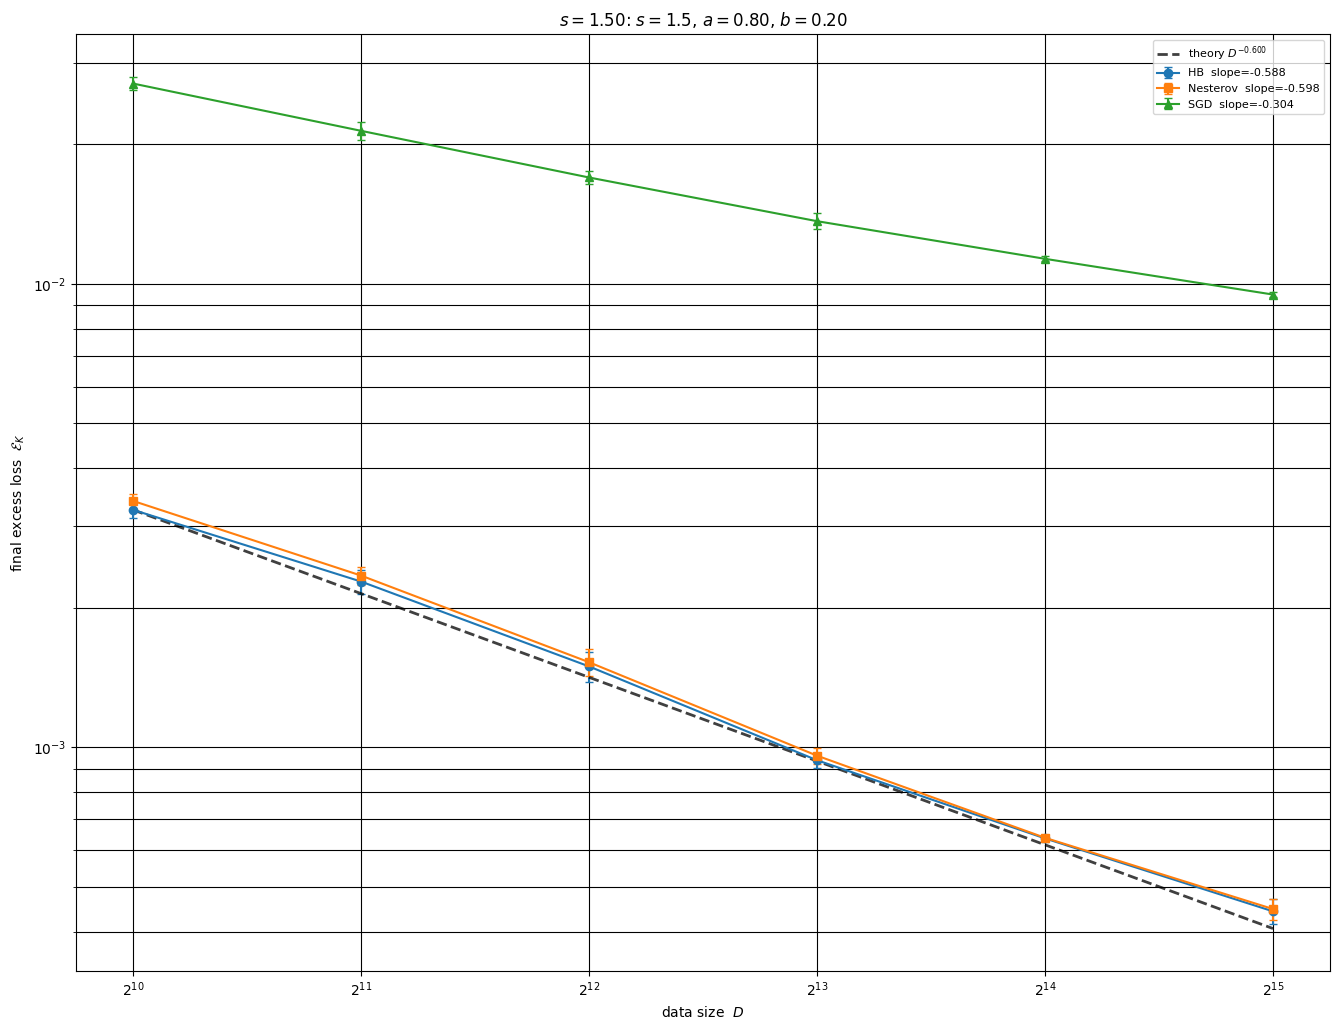

In [6]:
fig, axes = plt.subplots(1, len(S_CASES), figsize=(13.5, 10.4), sharey=False)
if len(S_CASES) == 1:
    axes = [axes]

markers = {'HB': 'o', 'Nesterov': 's', 'SGD': '^'}

for ax, case in zip(axes, S_CASES):
    key = case['key']
    payload = CASE_RESULTS[key]
    scaling = payload['scaling']
    results = payload['results']
    p_theory = scaling['p']
    slopes = {}

    for name in ALGOS:
        mean = np.array(results[name]['mean'])
        std = np.array(results[name]['std'])
        slope, intercept = np.polyfit(np.log(D_ARRAY), np.log(mean), 1)
        slopes[name] = slope
        ax.errorbar(D_LIST, mean, yerr=std, marker=markers[name], capsize=3,
                    linestyle='-', label=f'{name}  slope={slope:.3f}')

    anchor = np.array(results['HB']['mean'])[0]
    ref = anchor * (D_ARRAY / D_ARRAY[0]) ** (-p_theory)
    theory_label = rf'theory $D^{{-{p_theory:.3f}}}$'
    if scaling['p_star'] > p_theory + 1e-10:
        theory_label += rf'  ($p^*={scaling["p_star"]:.3f}$)'
    ax.plot(D_LIST, ref, linestyle='--', color=(0, 0, 0, 0.75), linewidth=2, label=theory_label)

    ax.set_xscale('log', base=2)
    ax.set_yscale('log')
    ax.set_xlabel('data size  $D$')
    ax.set_ylabel(r'final excess loss  $\mathcal{E}_K$')
    ax.set_title(rf"{case['title']}: $s={case['s']}$, $a={scaling['a']:.2f}$, $b={scaling['b']:.2f}$")
    ax.grid(True, which='both', color=(0, 0, 0, 0.3))
    ax.legend(fontsize=8)

    print(f"{case['title']}  s={case['s']:.3f}: theory slope = {-p_theory:.4f}")
    for name, sl in slopes.items():
        print(f'  measured slope {name:9s}: {sl:.4f}')
    print()

plt.tight_layout()
plt.show()


## 7. Training curves for representative $D$

These curves are diagnostic only. The scaling-law comparison above uses final excess loss at fixed
sample budget $D$.


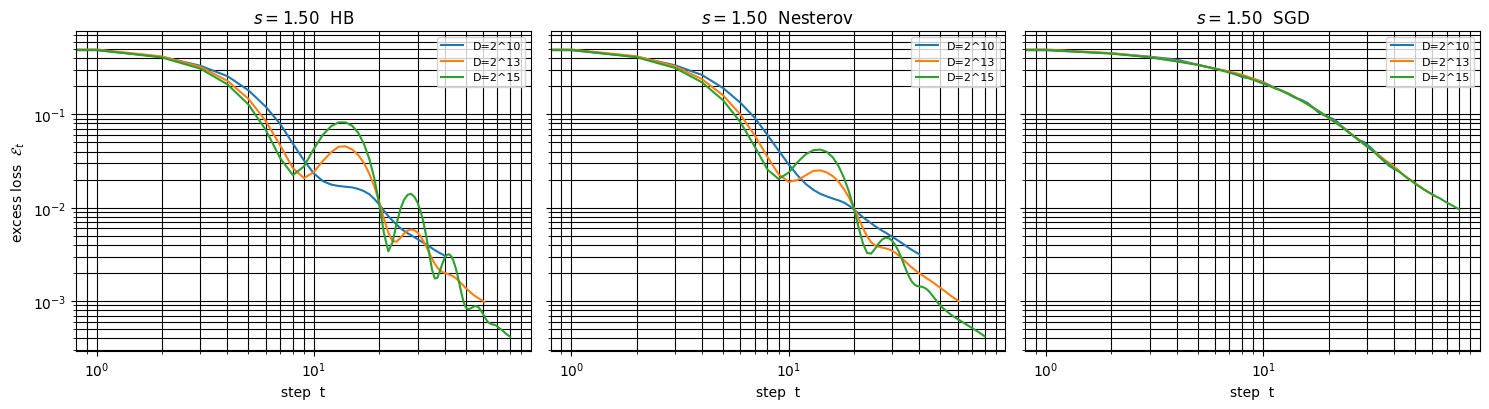

In [8]:
rep_D = [2 ** e for e in (D_EXPONENTS[0], D_EXPONENTS[len(D_EXPONENTS)//2], D_EXPONENTS[-1])]
fig, axes = plt.subplots(len(S_CASES), len(ALGOS), figsize=(15, 4.2 * len(S_CASES)), sharey='row')
if len(S_CASES) == 1:
    axes = np.array([axes])

for row, case in enumerate(S_CASES):
    key, s = case['key'], case['s']
    scaling = SCALINGS[key]
    lam, theta_star = build_problem(s=s)
    for col, (name, algo) in enumerate(ALGOS.items()):
        ax = axes[row, col]
        for D in rep_D:
            B, K, eta, rho = common_schedule(D, scaling)
            rng = cp.random.RandomState(D + 123 * row)
            _, curve = run_optimizer(algo, B, K, eta, rho, lam, theta_star, rng=rng)
            ax.plot(np.arange(len(curve)), curve, label=f'D=2^{int(np.log2(D))}')
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_title(f"{case['title']}  {name}")
        ax.set_xlabel('step  t')
        ax.grid(True, which='both', color=(0, 0, 0, 0.3))
        ax.legend(fontsize=8)
    axes[row, 0].set_ylabel(r'excess loss  $\mathcal{E}_t$')

plt.tight_layout()
plt.show()


## 8. Expected outcome

The experiment now tests the requested scaling directly.

- The default constants are $C_B=C_K=C_\rho=1$ and can be changed in Section 4.
- For each $s$, use $B=C_BD^{(2s+1)/(2s+2)}$ and
  $K=C_KD^{1/(2s+2)}$, so $BK\asymp C_BC_KD$.
- The stepsize is fixed at $\eta=0.05$.
- HB/NAG use $1-\rho=C_\rho D^{-1/(2s+2)}$; SGD keeps $\rho=0$ because it has no momentum term.
- The dashed reference lines use the optimal slope $-s/(s+1)$.

Finite-dimensional truncation, rounding, and stochastic variance can move the fitted slopes, but
the dashed reference lines show the theoretical polynomial rates implied by the requested scaling.
